# Лабораторная работа №4. Байесовская сеть

**Тема:** как погода и календарный контекст связаны со спросом на прокат велосипедов.

**Цель:** самостоятельно задать DAG, оценить условные вероятности и исследовать,
как новая информация меняет распределение спроса. Использован открытый датасет
**UCI Bike Sharing** и самостоятельно предложенная структура сети.

Это описательная модель исторических наблюдений: прогноз на будущий год и причинные
эффекты не оцениваются. Все расчёты воспроизводятся через **Run All**, интернет не нужен.

## 1. Выбор данных

Источник: [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset).
Fanaee-T, H. (2013), [DOI: 10.24432/C5W894](https://doi.org/10.24432/C5W894),
лицензия [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
Использован `hour.csv` официального архива; файл и авторский `Readme.txt` сохранены в `data/`.
Исходные данные не изменены. Датасет и DAG из примера задания не заимствовались.

**Один объект — один зарегистрированный час работы Capital Bikeshare в 2011–2012 годах.**
`cnt` — количество аренд за час. Это не отдельная поездка и не отдельный пользователь.
Число строк проверяем по файлу, а не копируем из карточки сайта.

| Исходные поля | Смысл и использование |
|---|---|
| `instant`, `dteday` | Идентификатор и дата; проверка уникальности и полноты календаря |
| `yr`, `mnth`, `season` | Год, месяц, код сезона; год включаем в сеть, сезон определяем явно по месяцу |
| `hr` | Час суток; преобразуем в четыре периода |
| `holiday`, `weekday`, `workingday` | Праздник, день недели, рабочий день; оставляем один `workingday` |
| `weathersit` | Категория погоды; объединяем два вида осадков |
| `temp`, `atemp` | Нормированные температура и ощущаемая температура; используем только `temp` |
| `hum`, `windspeed` | Влажность и скорость ветра; не включаем ради компактности сети |
| `casual`, `registered` | Компоненты числа аренд; исключаем, так как их сумма равна `cnt` |
| `cnt` | Количество аренд; преобразуем в низкий, средний и высокий спрос |

Сезон и время суток связаны с температурой, сезон — с погодой. Температура, осадки,
время суток и рабочий день связаны с удобством и целью поездок. Год учитывает изменение
масштаба сервиса, которое иначе смешалось бы с погодными зависимостями.

In [1]:
from pathlib import Path
import sys
import hashlib
import json
from math import prod
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display, Markdown

BASE = Path.cwd() if (Path.cwd() / "data/hour.csv").exists() else Path.cwd() / "bayesian"
assert (BASE / "data/hour.csv").is_file(), "Запустите из корня репозитория или bayesian/"
sys.path.insert(0, str(BASE.resolve()))
from bayes import DiscreteBayesNet
RESULTS = BASE / "results"
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"font.family":"DejaVu Sans", "figure.dpi":120,
                     "axes.spines.top":False, "axes.spines.right":False})
DATA_HASH = "e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f"
assert hashlib.sha256((BASE / "data/hour.csv").read_bytes()).hexdigest() == DATA_HASH
raw = pd.read_csv(BASE / "data/hour.csv", parse_dates=["dteday"])
display(raw.head())
print(f"Строк: {len(raw):,}; столбцов: {raw.shape[1]}; дат: {raw.dteday.nunique()}")
print(f"Период: {raw.dteday.min().date()} — {raw.dteday.max().date()}")

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Строк: 17,379; столбцов: 17; дат: 731
Период: 2011-01-01 — 2012-12-31


## 2. Исследование и подготовка данных

Проверим пропуски, дубликаты и календарную полноту. Отсутствующая строка часа
и пропущенное значение в существующей строке — разные проблемы.

In [2]:
audit = pd.DataFrame({"dtype":raw.dtypes.astype(str), "missing":raw.isna().sum(), "unique":raw.nunique()})
display(audit)
assert raw.isna().sum().sum() == 0
assert not raw.duplicated().any()
assert not raw.duplicated(["dteday", "hr"]).any()
assert (raw.casual + raw.registered == raw.cnt).all()
assert raw.temp.between(0, 1).all()
assert raw.hr.between(0, 23).all()
assert set(raw.weathersit) <= {1, 2, 3, 4}
assert (raw.yr == raw.dteday.dt.year - 2011).all()
assert (raw.mnth == raw.dteday.dt.month).all()
assert (raw.workingday == (raw.weekday.isin([1,2,3,4,5]) & (raw.holiday == 0))).all()
full_hours = pd.date_range(raw.dteday.min(), raw.dteday.max() + pd.Timedelta(hours=23), freq="h")
observed_hours = pd.DatetimeIndex(raw.dteday + pd.to_timedelta(raw.hr, unit="h"))
missing_hours = full_hours.difference(observed_hours)
print("Дубликатов строк и пар дата–час: 0")
print("Отсутствующих часов в полном календаре:", len(missing_hours))
print("Исходные категории погоды:")
display(raw.weathersit.value_counts().sort_index().rename("n").to_frame())
display(raw[["temp", "cnt", "hum", "windspeed"]].describe().round(3))
audit.to_csv(RESULTS / "raw_audit.csv", encoding="utf-8-sig")

,dtype,missing,unique
instant,int64,0,17379
dteday,datetime64[us],0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
hr,int64,0,24
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,4


Дубликатов строк и пар дата–час: 0
Отсутствующих часов в полном календаре: 165
Исходные категории погоды:


,n
weathersit,
1,11413
2,4544
3,1419
4,3


,temp,cnt,hum,windspeed
count,17379.000,17379.000,17379.000,17379.000
mean,0.497,189.463,0.627,0.190
std,0.193,181.388,0.193,0.122
min,0.020,1.000,0.000,0.000
25%,0.340,40.000,0.480,0.104
50%,0.500,142.000,0.630,0.194
75%,0.660,281.000,0.780,0.254
max,1.000,977.000,1.000,0.851


В существующих строках пропусков нет; заполнять значения или удалять объекты не требуется.
Отсутствующим часам не подставляем нулевой спрос: причины отсутствия из файла неизвестны.
Поэтому распределение относится к **зарегистрированному часу**, а не обязательно к
равномерно выбранному часу полного календаря.

### Правила дискретизации, заданные до построения сети

| Переменная | Состояния | Правило и обоснование |
|---|---|---|
| `season` | Зима, Весна, Лето, Осень | По месяцу: декабрь–февраль, март–май, июнь–август, сентябрь–ноябрь |
| `period` | Ночь, Утро, День, Вечер | 00–05, 06–11, 12–17, 18–23; четыре интервала вместо 24 состояний |
| `temperature` | Прохладно, Умеренно, Тепло | `temp`: <0.35, [0.35; 0.65), ≥0.65 |
| `weather` | Ясно, Туман, Осадки | Исходный код 1, код 2, объединённые коды 3 и 4 |
| `workingday` | Выходной, Рабочий | 0 и 1; «Выходной» включает праздники |
| `year` | 2011, 2012 | Исходный `yr`: 0 и 1 |
| `demand` | Низкий, Средний, Высокий | `cnt` <100, 100–299, ≥300 аренд за час |

Пороги температуры имеют относительный смысл на нормированной шкале датасета; это не
универсальные границы комфорта. Пороги спроса легко объяснить числом аренд и применить
к новым данным. Пороги фиксированные, не подобраны по качеству модели и не являются
квантилями. Дискретизация уменьшает размер CPT, но теряет различия внутри интервалов,
например утренний час пик внутри периода 06–11.

Код погоды 4 встречается всего **3 раза**: отдельная категория была бы ненадёжной.
Объединяем с кодом 3 по общему признаку осадков. «Ясно» допускает облачность, «Туман»
обозначает всю группу mist/cloudy. Сезон определяем по месяцу, чтобы правило не зависело
от названий кодов `season` в разных версиях описания. Это наше преобразование, а не
исправление исходных значений.

,variable,state,n,share
0,season,Зима,4253,0.2447
1,season,Весна,4398,0.2531
2,season,Лето,4403,0.2534
3,season,Осень,4325,0.2489
4,period,Ночь,4276,0.2460
5,period,Утро,4360,0.2509
6,period,День,4375,0.2517
7,period,Вечер,4368,0.2513
8,temperature,Прохладно,4770,0.2745
9,temperature,Умеренно,8192,0.4714


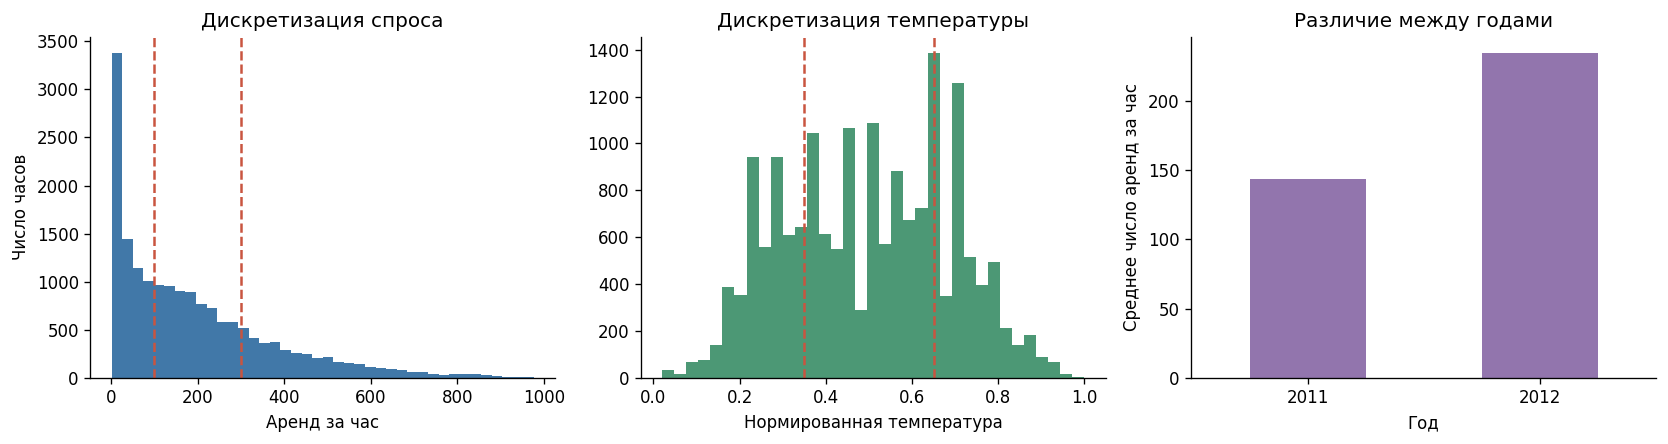

In [3]:
STATES = {
    "season":["Зима", "Весна", "Лето", "Осень"],
    "period":["Ночь", "Утро", "День", "Вечер"],
    "temperature":["Прохладно", "Умеренно", "Тепло"],
    "weather":["Ясно", "Туман", "Осадки"],
    "workingday":["Выходной", "Рабочий"],
    "year":["2011", "2012"], "demand":["Низкий", "Средний", "Высокий"],
}
month_to_season = {m:s for months, s in [([12,1,2],"Зима"), ([3,4,5],"Весна"),
                                        ([6,7,8],"Лето"), ([9,10,11],"Осень")]
                   for m in months}
data = pd.DataFrame({
    "season":raw.mnth.map(month_to_season),
    "period":pd.cut(raw.hr, [-1,5,11,17,23], labels=STATES["period"]).astype(str),
    "temperature":pd.cut(raw.temp, [-np.inf,.35,.65,np.inf], right=False,
                          labels=STATES["temperature"]).astype(str),
    "weather":raw.weathersit.map({1:"Ясно", 2:"Туман", 3:"Осадки", 4:"Осадки"}),
    "workingday":raw.workingday.map({0:"Выходной", 1:"Рабочий"}),
    "year":raw.yr.map({0:"2011", 1:"2012"}),
    "demand":pd.cut(raw.cnt, [-np.inf,100,300,np.inf], right=False,
                    labels=STATES["demand"]).astype(str),
})
assert not data.isna().any().any()
assert len(data) == len(raw)
state_counts = pd.concat([
    data[v].value_counts().reindex(states, fill_value=0).rename_axis("state")
    .reset_index(name="n").assign(variable=v) for v, states in STATES.items()
], ignore_index=True)[["variable", "state", "n"]]
state_counts["share"] = state_counts.n / len(data)
display(state_counts.round(4))
state_counts.to_csv(RESULTS / "state_counts.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(raw.cnt, bins=40, color="#4178a8")
for t in [100,300]: axes[0].axvline(t, color="#c95540", linestyle="--")
axes[0].set(xlabel="Аренд за час", ylabel="Число часов", title="Дискретизация спроса")
axes[1].hist(raw.temp, bins=35, color="#4c9875")
for t in [.35,.65]: axes[1].axvline(t, color="#c95540", linestyle="--")
axes[1].set(xlabel="Нормированная температура", title="Дискретизация температуры")
raw.groupby("yr").cnt.mean().rename(index={0:"2011",1:"2012"}).plot.bar(ax=axes[2], color="#9275ad", rot=0)
axes[2].set(xlabel="Год", ylabel="Среднее число аренд за час", title="Различие между годами")
fig.tight_layout()
fig.savefig(RESULTS / "data_overview.png", bbox_inches="tight")
plt.show()

Количество строк само по себе не гарантирует достаточность данных: ниже проверим
наполненность каждой конфигурации родителей. Соседние часы зависимы; 17 тысяч строк
не означают столько же независимых повторений эксперимента.

**Режим оценки.** Параметры оцениваются на всех наблюдениях для описания исторической
выборки. Сопоставление CPT с частотами тех же данных проверяет расчёт, а не обобщающую
способность. Train/test, accuracy и baseline классификации не используются, поскольку
заявлений о качестве прогноза нет. Для прогноза понадобятся временной holdout,
сравнение с базовым распределением спроса, log loss и проверка калибровки.

## 3. Вопросы до построения сети

1. Как изменится вероятность **высокого спроса**, если известно, что **тепло**?
   Сравнить $P(D=высокий)$ и $P(D=высокий\mid T=тепло)$.
2. Какова вероятность высокого спроса, если одновременно **тепло и есть осадки**?
   Сравнить с исходной вероятностью и с одним условием «тепло».
3. Как меняется распределение спроса, если это **дневные часы рабочего дня**?
4. Обратный запрос: как меняется вероятность **тепла**, если наблюдается **высокий спрос**?
   Это обновление знания, а не влияние спроса на погоду.

В отдельном эксперименте последовательно раскроем:
**день → рабочий день → тепло → осадки → 2012 год**.

## 4. Построение графа

Структура предложена вручную по смыслу переменных. Обучение структуры и выбор стрелок
по корреляциям не выполняются.

| Ребро | Зависимость и основание направления |
|---|---|
| `season → temperature` | Сезонный цикл связан с температурой; календарный контекст предшествует измерению |
| `period → temperature` | Дневной ход температуры; час суток не определяется температурой |
| `season → weather` | Частоты погодных условий меняются по сезонам; сезон задаёт контекст |
| `temperature → demand` | Температура связана с комфортом поездки; спрос не определяет температуру воздуха |
| `weather → demand` | Осадки связаны с удобством езды; направление от условий поездки к числу аренд |
| `period → demand` | Суточный распорядок меняет потребность в поездках |
| `workingday → demand` | Рабочие и свободные дни отличаются целями поездок; календарь не определяется арендой |
| `year → demand` | Индикатор развития сервиса и популярности; не самостоятельный физический механизм |

Стрелки задают факторизацию, а не доказанную причинность. Прямой связи сезона со спросом
нет: влияние передаётся через температуру и погоду. Это упрощение игнорирует, например,
световой день и отпуска. Корневые переменные считаются независимыми; температура и
погода независимы при заданных сезоне и периоде. Реальная погода может нарушать последнее допущение.

$$P(S,H,W,Y,T,R,D)=P(S)P(H)P(W)P(Y)P(T\mid S,H)P(R\mid S)P(D\mid T,R,H,W,Y).$$

$S$ — сезон, $H$ — время суток, $W$ — рабочий день, $Y$ — год,
$T$ — температура, $R$ — погода, $D$ — спрос.

Топологический порядок: season → period → workingday → year → weather → temperature → demand
Число полных состояний: 1728


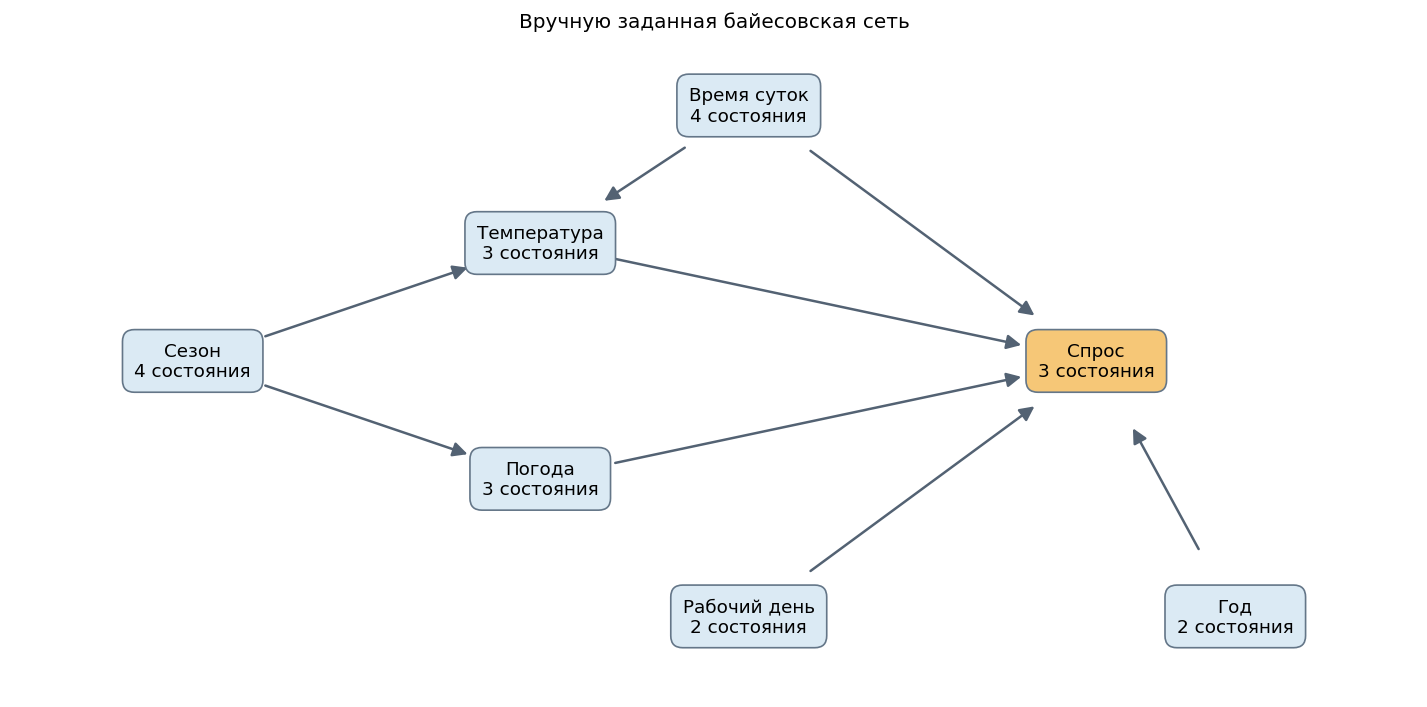

In [4]:
PARENTS = {
    "season":[], "period":[], "workingday":[], "year":[],
    "temperature":["season","period"], "weather":["season"],
    "demand":["temperature","weather","period","workingday","year"],
}
model = DiscreteBayesNet(STATES, PARENTS, alpha=1.0)
print("Топологический порядок:", " → ".join(model.order))
print("Число полных состояний:", prod(map(len, STATES.values())))
# TopologicalSorter в конструкторе отклоняет граф с циклом.
positions = {"season":(0,1.2), "period":(4,3.8), "temperature":(2.5,2.4),
             "weather":(2.5,0), "demand":(6.5,1.2), "workingday":(4,-1.4), "year":(7.5,-1.4)}
labels = {"season":"Сезон\n4 состояния", "period":"Время суток\n4 состояния",
          "temperature":"Температура\n3 состояния", "weather":"Погода\n3 состояния",
          "demand":"Спрос\n3 состояния", "workingday":"Рабочий день\n2 состояния", "year":"Год\n2 состояния"}
fig, ax = plt.subplots(figsize=(12,6))
for child, parents in PARENTS.items():
    for parent in parents:
        ax.add_patch(FancyArrowPatch(positions[parent], positions[child], arrowstyle="-|>",
                                    mutation_scale=18, linewidth=1.5, color="#536273",
                                    shrinkA=46, shrinkB=46, zorder=1))
for node, (x,y) in positions.items():
    ax.text(x,y,labels[node], ha="center", va="center", fontsize=11,
            bbox=dict(boxstyle="round,pad=.65", facecolor="#f6c777" if node=="demand" else "#dbeaf4",
                      edgecolor="#647688"), zorder=2)
ax.set(xlim=(-1.3,8.8), ylim=(-2.2,4.5), title="Вручную заданная байесовская сеть")
ax.axis("off")
fig.tight_layout()
fig.savefig(RESULTS / "bayesian_network.png", bbox_inches="tight")
plt.show()

## 5. Оценка CPT и достаточность наблюдений

Для каждой конфигурации родителей используем симметричный prior Дирихле с $\alpha=1$
**на каждое состояние**. Апостериорное среднее:

$$\widehat P(X=x\mid Pa(X)=u)=\frac{N(x,u)+\alpha}{N(u)+r_X\alpha}.$$

Это сглаживание Лапласа, не MAP и не BDeu с общим эквивалентным объёмом выборки.
Сглаживание устраняет нули, но не создаёт информацию: пустая конфигурация родителей
получает равномерное распределение. Для спроса добавляются три псевдонаблюдения на
каждую строку CPT, что особенно влияет на редкие сочетания.

В `bayes.py` реализованы подсчёт частот, произведение CPT и точное суммирование.
Для семи дискретных переменных специализированная библиотека не обязательна;
формулы и реализация доступны для проверки.

In [5]:
model.fit(data)
coverage_rows = []
for node, ps in PARENTS.items():
    cpt = model.cpts[node]
    parent_counts = cpt.drop_duplicates(ps) if ps else cpt.iloc[:1]
    q = prod(len(STATES[p]) for p in ps)
    coverage_rows.append({"variable":node, "parent_configs":q,
        "free_parameters":q*(len(STATES[node])-1), "min_n":parent_counts.N_parent.min(),
        "median_n":parent_counts.N_parent.median(), "empty_configs":int((parent_counts.N_parent==0).sum()),
        "configs_under_20":int((parent_counts.N_parent<20).sum())})
    cpt.to_csv(RESULTS / f"cpt_{node}.csv", index=False, encoding="utf-8-sig")
coverage = pd.DataFrame(coverage_rows).set_index("variable")
display(coverage)
coverage.to_csv(RESULTS / "cpt_coverage.csv", encoding="utf-8-sig")
print("Всего свободных параметров:", coverage.free_parameters.sum())
demand_contexts = model.cpts["demand"].drop_duplicates(PARENTS["demand"])
print("Наиболее редкие конфигурации родителей спроса:")
display(demand_contexts.nsmallest(10,"N_parent")[PARENTS["demand"] + ["N_parent"]])
for node, cpt in model.cpts.items():
    ps = PARENTS[node]
    sums = cpt.groupby(ps).probability.sum() if ps else pd.Series([cpt.probability.sum()])
    np.testing.assert_allclose(sums, 1, atol=1e-12)
    assert (cpt.probability > 0).all()
    expected = (cpt.n + model.alpha)/(cpt.N_parent + len(STATES[node])*model.alpha)
    np.testing.assert_allclose(cpt.probability, expected)
np.testing.assert_allclose(model.joint.probability.sum(), 1, atol=1e-12)
print("Все CPT и совместное распределение нормированы.")

,parent_configs,free_parameters,min_n,median_n,empty_configs,configs_under_20
variable,,,,,,
season,1,3,17379,17379.0,0,0
period,1,3,17379,17379.0,0,0
workingday,1,1,17379,17379.0,0,0
year,1,1,17379,17379.0,0,0
temperature,16,32,1018,1086.0,0,0
weather,4,8,4253,4361.5,0,0
demand,144,288,0,84.0,1,27


Всего свободных параметров: 336
Наиболее редкие конфигурации родителей спроса:


,temperature,weather,period,workingday,year,N_parent
399,Тепло,Осадки,Утро,Выходной,2012,0
387,Тепло,Осадки,Ночь,Выходной,2012,1
384,Тепло,Осадки,Ночь,Выходной,2011,3
390,Тепло,Осадки,Ночь,Рабочий,2011,5
396,Тепло,Осадки,Утро,Выходной,2011,6
402,Тепло,Осадки,Утро,Рабочий,2011,6
123,Прохладно,Осадки,День,Выходной,2012,7
420,Тепло,Осадки,Вечер,Выходной,2011,7
240,Умеренно,Осадки,Ночь,Выходной,2011,9
393,Тепло,Осадки,Ночь,Рабочий,2012,9


Все CPT и совместное распределение нормированы.


In [6]:
coverage_d = coverage.loc["demand"]
display(Markdown(
    f"У спроса **{int(coverage_d.parent_configs)}** конфигурации родителей и "
    f"**{int(coverage_d.free_parameters)}** свободных параметров. "
    f"Пустых: **{int(coverage_d.empty_configs)}**, с менее чем 20 часами: "
    f"**{int(coverage_d.configs_under_20)}**. Медиана наполненности — "
    f"**{coverage_d.median_n:.0f}** часов. Общий объём достаточен для учебного описания "
    "частых условий, но не гарантирует надёжность каждой строки CPT. Редкие сочетания "
    "нужно читать вместе с N_parent; сглаживание не устраняет эту неопределённость."
))

У спроса **144** конфигурации родителей и **288** свободных параметров. Пустых: **1**, с менее чем 20 часами: **27**. Медиана наполненности — **84** часов. Общий объём достаточен для учебного описания частых условий, но не гарантирует надёжность каждой строки CPT. Редкие сочетания нужно читать вместе с N_parent; сглаживание не устраняет эту неопределённость.

### Несколько условных таблиц

Рассмотрим температуру днём по сезонам, погоду по сезонам и высокий спрос днём в рабочие
дни 2012 года. Рядом со сглаженной вероятностью показываем MLE и размер группы.

In [7]:
temp_cpt = model.cpts["temperature"].query("period == 'День'")
weather_cpt = model.cpts["weather"]
demand_cpt = model.cpts["demand"].query(
    "period == 'День' and workingday == 'Рабочий' and year == '2012' and demand == 'Высокий'")
print("Температура | сезон, дневные часы:")
display(temp_cpt[["season","temperature","n","N_parent","mle","probability"]].round(4))
print("Погода | сезон:")
display(weather_cpt[["season","weather","n","N_parent","mle","probability"]].round(4))
print("Высокий спрос | дневные часы рабочего дня 2012 года, температура, погода:")
display(demand_cpt[["temperature","weather","n","N_parent","mle","probability"]].round(4))
mask = ((data.temperature=="Тепло") & (data.weather=="Ясно") & (data.period=="День") &
        (data.workingday=="Рабочий") & (data.year=="2012"))
row = demand_cpt.query("temperature == 'Тепло' and weather == 'Ясно'").iloc[0]
assert row.N_parent == mask.sum()
assert row.n == (raw.loc[mask,"cnt"] >= 300).sum()
assert np.isclose(row.mle, (raw.loc[mask,"cnt"] >= 300).mean())
print("Выбранная строка CPT совпадает с прямым подсчётом по исходному cnt.")

Температура | сезон, дневные часы:


,season,temperature,n,N_parent,mle,probability
6,Зима,Прохладно,612,1082,0.5656,0.5650
7,Зима,Умеренно,466,1082,0.4307,0.4304
8,Зима,Тепло,4,1082,0.0037,0.0046
18,Весна,Прохладно,114,1104,0.1033,0.1039
19,Весна,Умеренно,712,1104,0.6449,0.6441
20,Весна,Тепло,278,1104,0.2518,0.2520
30,Лето,Прохладно,0,1104,0.0000,0.0009
31,Лето,Умеренно,63,1104,0.0571,0.0578
32,Лето,Тепло,1041,1104,0.9429,0.9413
42,Осень,Прохладно,66,1085,0.0608,0.0616


Погода | сезон:


,season,weather,n,N_parent,mle,probability
0,Зима,Ясно,2580,4253,0.6066,0.6064
1,Зима,Туман,1295,4253,0.3045,0.3045
2,Зима,Осадки,378,4253,0.0889,0.0891
3,Весна,Ясно,2770,4398,0.6298,0.6296
4,Весна,Туман,1214,4398,0.2760,0.2761
5,Весна,Осадки,414,4398,0.0941,0.0943
6,Лето,Ясно,3351,4403,0.7611,0.7608
7,Лето,Туман,831,4403,0.1887,0.1888
8,Лето,Осадки,221,4403,0.0502,0.0504
9,Осень,Ясно,2712,4325,0.6271,0.6268


Высокий спрос | дневные часы рабочего дня 2012 года, температура, погода:


,temperature,weather,n,N_parent,mle,probability
35,Прохладно,Ясно,17,87,0.1954,0.2000
83,Прохладно,Туман,11,79,0.1392,0.1463
131,Прохладно,Осадки,1,44,0.0227,0.0426
179,Умеренно,Ясно,228,469,0.4861,0.4852
227,Умеренно,Туман,62,193,0.3212,0.3214
275,Умеренно,Осадки,11,51,0.2157,0.2222
323,Тепло,Ясно,267,435,0.6138,0.6119
371,Тепло,Туман,62,116,0.5345,0.5294
419,Тепло,Осадки,6,19,0.3158,0.3182


Выбранная строка CPT совпадает с прямым подсчётом по исходному cnt.


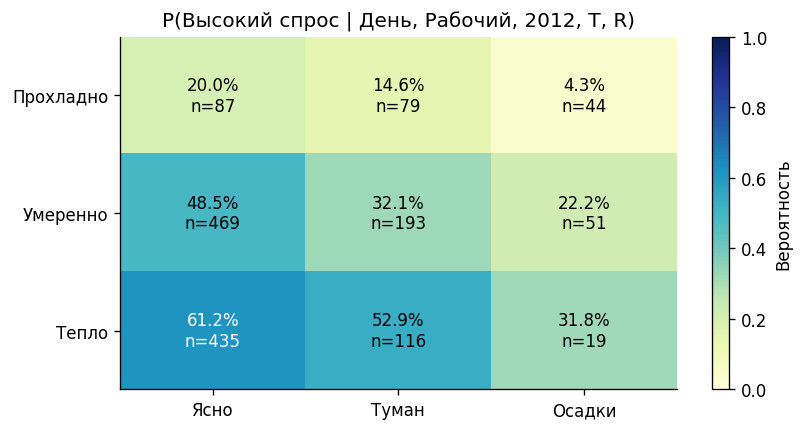

Для тёплого дневного часа рабочего дня 2012 года вероятность высокого спроса: **61.2%** при ясной погоде (n=435) и **31.8%** при осадках (n=19). Даже большой спрос при осадках не является ошибкой сам по себе: отобран тёплый дневной час 2012 года, а категория включает лёгкий дождь. Нельзя переносить этот результат на сильный ливень или средний час за оба года.

**Температура и погода.** Доля тёплых дневных часов летом по CPT — 94,1%, зимой — 0,46%: ожидаемый сезонный контраст. Летних прохладных дневных часов в данных нет, но сглаженная вероятность равна 1/1107 ≈ 0,09%. Это вклад prior, а не обнаруженное наблюдение. Частота осадков летом около 5%, в остальные сезоны — около 9%; это свойство этих двух лет, не универсальная климатическая норма. При больших N_parent MLE и сглаженная оценка близки. Пустая конфигурация «тепло, осадки, утро, выходной, 2012» получает по 1/3 для каждого уровня спроса исключительно из prior. Такие ответы нельзя представлять как измеренный эффект.

In [8]:
fig, ax = plt.subplots(figsize=(7,3.7))
heat = demand_cpt.pivot(index="temperature", columns="weather", values="probability").reindex(
    index=STATES["temperature"], columns=STATES["weather"])
counts_heat = demand_cpt.pivot(index="temperature", columns="weather", values="N_parent").reindex_like(heat)
im = ax.imshow(heat, vmin=0, vmax=1, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(3), heat.columns)
ax.set_yticks(range(3), heat.index)
for i in range(3):
    for j in range(3):
        value = heat.iloc[i,j]
        ax.text(j,i,f"{value:.1%}\nn={int(counts_heat.iloc[i,j])}", ha="center", va="center",
                color="white" if value>.6 else "black")
ax.set_title("P(Высокий спрос | День, Рабочий, 2012, T, R)")
fig.colorbar(im, ax=ax, label="Вероятность")
fig.tight_layout()
fig.savefig(RESULTS / "demand_cpt.png", bbox_inches="tight")
plt.show()
warm = demand_cpt.query("temperature == 'Тепло'").set_index("weather")
display(Markdown(
    f"Для тёплого дневного часа рабочего дня 2012 года вероятность высокого спроса: "
    f"**{warm.loc['Ясно','probability']:.1%}** при ясной погоде "
    f"(n={int(warm.loc['Ясно','N_parent'])}) и **{warm.loc['Осадки','probability']:.1%}** "
    f"при осадках (n={int(warm.loc['Осадки','N_parent'])}). "
    "Даже большой спрос при осадках не является ошибкой сам по себе: отобран тёплый "
    "дневной час 2012 года, а категория включает лёгкий дождь. Нельзя переносить "
    "этот результат на сильный ливень или средний час за оба года."
))

display(Markdown(
    "**Температура и погода.** Доля тёплых дневных часов летом по CPT — 94,1%, "
    "зимой — 0,46%: ожидаемый сезонный контраст. Летних прохладных дневных часов "
    "в данных нет, но сглаженная вероятность равна 1/1107 ≈ 0,09%. "
    "Это вклад prior, а не обнаруженное наблюдение. Частота осадков летом около 5%, "
    "в остальные сезоны — около 9%; это свойство этих двух лет, не универсальная климатическая норма. "
    "При больших N_parent MLE и сглаженная оценка близки. Пустая конфигурация "
    "«тепло, осадки, утро, выходной, 2012» получает по 1/3 для каждого уровня спроса "
    "исключительно из prior. Такие ответы нельзя представлять как измеренный эффект."
))


## 6. Вероятностный вывод

Фиксируем evidence, суммируем по скрытым переменным $Z$ и нормируем:

$$P(Q=q\mid E=e)=\frac{\sum_z P(Q=q,E=e,Z=z)}{\sum_{q',z} P(Q=q',E=e,Z=z)}.$$

Всего 1 728 состояний, поэтому используем **точный перебор**, без Монте-Карло.
Точность алгоритма для заданных CPT не означает, что модель идеально описывает
реальность. При большом числе вершин понадобятся более экономные алгоритмы,
например variable elimination.

In [9]:
def empirical(target, state, evidence):
    mask = pd.Series(True, index=data.index)
    for node, value in evidence.items():
        mask &= data[node].eq(value)
    n = int(mask.sum())
    return n, float(data.loc[mask,target].eq(state).mean()) if n else np.nan

QUESTIONS = [
    ("Q1: тепло", "demand", "Высокий", {"temperature":"Тепло"}),
    ("Q2: тепло и осадки", "demand", "Высокий", {"temperature":"Тепло","weather":"Осадки"}),
    ("Q3: день и рабочий день", "demand", "Высокий", {"period":"День","workingday":"Рабочий"}),
    ("Q4: высокий спрос → знание о температуре", "temperature", "Тепло", {"demand":"Высокий"}),
]
query_rows = []
for question, target, state, evidence in QUESTIONS:
    prior = float(model.query(target)[state])
    posterior = float(model.query(target,evidence)[state])
    n, frequency = empirical(target,state,evidence)
    query_rows.append({"question":question, "target":target, "state":state,
        "prior":prior, "posterior":posterior, "delta_pp":100*(posterior-prior),
        "n_evidence":n, "empirical_posterior":frequency, "empirical_p_evidence":n/len(data),
        "model_p_evidence":model.evidence_probability(evidence)})
queries = pd.DataFrame(query_rows).set_index("question")
display(queries.round(4))
queries.to_csv(RESULTS / "queries.csv", encoding="utf-8-sig")
print("Полное распределение спроса для Q3:")
display(pd.DataFrame({"До evidence":model.query("demand"),
                      "День и рабочий день":model.query("demand",QUESTIONS[2][3])}).round(4))

,target,state,prior,posterior,delta_pp,n_evidence,empirical_posterior,empirical_p_evidence,model_p_evidence
question,,,,,,,,,
Q1: тепло,demand,Высокий,0.2298,0.4060,17.6208,4417,0.4089,0.2542,0.2547
Q2: тепло и осадки,demand,Высокий,0.2298,0.3250,9.5160,155,0.3290,0.0089,0.0156
Q3: день и рабочий день,demand,Высокий,0.2298,0.2951,6.5319,2989,0.2954,0.1720,0.1719
Q4: высокий спрос → знание о температуре,temperature,Тепло,0.2547,0.4501,19.5328,3921,0.4606,0.2256,0.2298


Полное распределение спроса для Q3:


,До evidence,День и рабочий день
demand,,
Низкий,0.3945,0.1151
Средний,0.3757,0.5897
Высокий,0.2298,0.2951


In [10]:
q1, q2, q3, q4 = [queries.iloc[i] for i in range(4)]
display(Markdown(f"""
**Ответы на вопросы.**

1. При тепле вероятность высокого спроса меняется с **{q1.prior:.1%}** до
   **{q1.posterior:.1%}** ({q1.delta_pp:+.1f} п.п.). Температура даёт информацию
   через прямое ребро к спросу, а также уточняет сезон и время суток.
2. При тепле и осадках получаем **{q2.posterior:.1%}**. Относительно одного тепла
   изменение составляет **{100*(q2.posterior-q1.posterior):+.1f} п.п.**
   Благоприятная температура вместе с неблагоприятной погодой даёт иной результат,
   чем любое из условий по отдельности.
3. Для дневных часов рабочего дня вероятность высокого спроса — **{q3.posterior:.1%}**
   против **{q3.prior:.1%}**. Работают прямые связи времени и типа дня со спросом;
   период суток также уточняет температуру.
4. При высоком спросе вероятность тепла меняется с **{q4.prior:.1%}** до
   **{q4.posterior:.1%}**. Знание о следствии помогает судить об условиях, при которых
   оно наблюдается. Это не значит, что увеличение числа аренд нагревает воздух.

`empirical_posterior` — частота в тех же данных, а не независимая проверка прогнозов.
Отличие от сетевого вывода ожидаемо: сеть накладывает ограничения независимости и
применяет сглаживание. `n_evidence` показывает представленность сценария в выборке.
"""))
display(Markdown(
    f"**Проверка ограничений структуры.** Частота сочетания «тепло и осадки» "
    f"в данных — {q2.empirical_p_evidence:.2%}, а модельная P(evidence) — "
    f"{q2.model_p_evidence:.2%}. Различие заметное: независимость температуры и погоды "
    "при заданном сезоне/периоде и другие упрощения не воспроизводят все сочетания. "
    "Близость отдельных условных вероятностей спроса к частотам не доказывает "
    "точности полного совместного распределения."
))



**Ответы на вопросы.**

1. При тепле вероятность высокого спроса меняется с **23.0%** до
   **40.6%** (+17.6 п.п.). Температура даёт информацию
   через прямое ребро к спросу, а также уточняет сезон и время суток.
2. При тепле и осадках получаем **32.5%**. Относительно одного тепла
   изменение составляет **-8.1 п.п.**
   Благоприятная температура вместе с неблагоприятной погодой даёт иной результат,
   чем любое из условий по отдельности.
3. Для дневных часов рабочего дня вероятность высокого спроса — **29.5%**
   против **23.0%**. Работают прямые связи времени и типа дня со спросом;
   период суток также уточняет температуру.
4. При высоком спросе вероятность тепла меняется с **25.5%** до
   **45.0%**. Знание о следствии помогает судить об условиях, при которых
   оно наблюдается. Это не значит, что увеличение числа аренд нагревает воздух.

`empirical_posterior` — частота в тех же данных, а не независимая проверка прогнозов.
Отличие от сетевого вывода ожидаемо: сеть накладывает ограничения независимости и
применяет сглаживание. `n_evidence` показывает представленность сценария в выборке.


**Проверка ограничений структуры.** Частота сочетания «тепло и осадки» в данных — 0.89%, а модельная P(evidence) — 1.56%. Различие заметное: независимость температуры и погоды при заданном сезоне/периоде и другие упрощения не воспроизводят все сочетания. Близость отдельных условных вероятностей спроса к частотам не доказывает точности полного совместного распределения.

## 7. Эксперимент с evidence

Интересующая переменная — спрос. Условия **накапливаются**, предыдущие не заменяются.
Показываем все три вероятности, изменение P(Высокий) и количество часов,
удовлетворяющих всем условиям одновременно.

,Низкий,Средний,Высокий,n_evidence,empirical_high,model_p_evidence,delta_high_pp
step,,,,,,,
Ничего не известно,0.3945,0.3757,0.2298,17379,0.2256,1.0000,0.0000
+ День,0.1050,0.4909,0.4041,4375,0.4016,0.2517,17.4248
+ Рабочий день,0.1151,0.5897,0.2951,2989,0.2954,0.1719,-10.8928
+ Тепло,0.0166,0.5822,0.4012,1122,0.4100,0.0633,10.6052
+ Осадки,0.1366,0.5452,0.3182,38,0.3158,0.0042,-8.2998
+ 2012 год,0.1818,0.5000,0.3182,19,0.3158,0.0021,0.0000


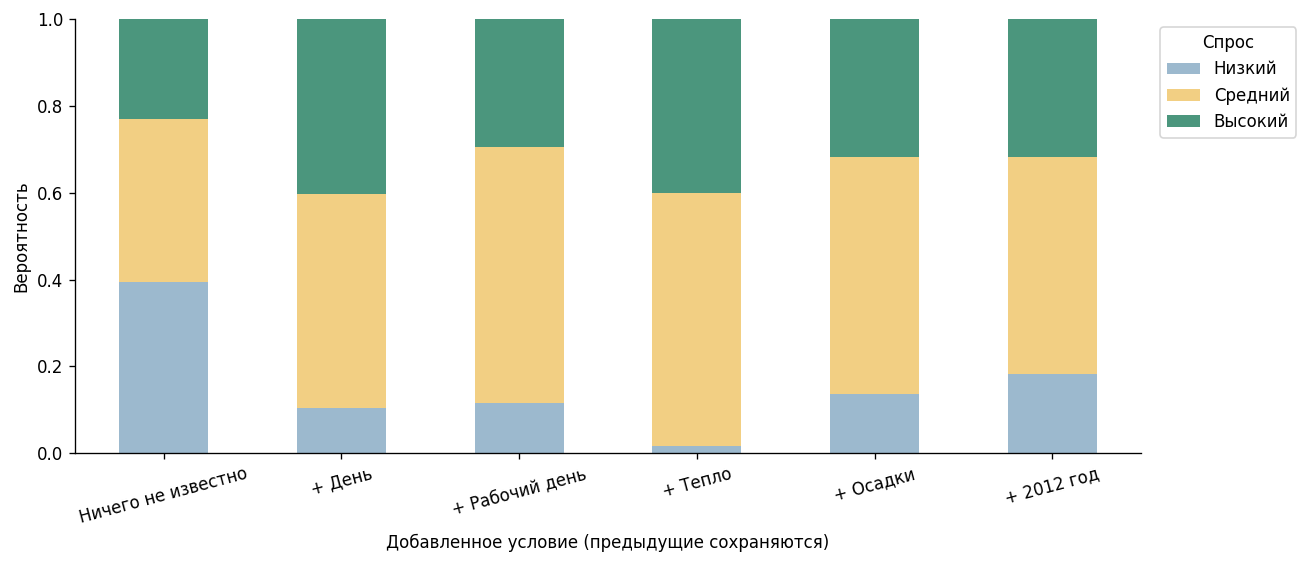

In [11]:
steps = [("Ничего не известно",None), ("+ День",("period","День")),
         ("+ Рабочий день",("workingday","Рабочий")), ("+ Тепло",("temperature","Тепло")),
         ("+ Осадки",("weather","Осадки")), ("+ 2012 год",("year","2012"))]
evidence, evidence_rows, evidence_history = {}, [], []
for step, addition in steps:
    if addition: evidence[addition[0]] = addition[1]
    evidence_history.append(evidence.copy())
    distribution = model.query("demand",evidence)
    n, frequency = empirical("demand","Высокий",evidence)
    evidence_rows.append({"step":step, **distribution.to_dict(), "n_evidence":n,
        "empirical_high":frequency, "model_p_evidence":model.evidence_probability(evidence)})
evidence_table = pd.DataFrame(evidence_rows).set_index("step")
evidence_table["delta_high_pp"] = evidence_table["Высокий"].diff().fillna(0)*100
display(evidence_table.round(4))
evidence_table.to_csv(RESULTS / "evidence_experiment.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11,4.8))
evidence_table[STATES["demand"]].plot.bar(stacked=True, ax=ax, color=["#9cb9ce","#f2cf83","#4b967d"], rot=15)
ax.set(xlabel="Добавленное условие (предыдущие сохраняются)", ylabel="Вероятность", ylim=(0,1))
ax.legend(title="Спрос", bbox_to_anchor=(1.01,1), loc="upper left")
fig.tight_layout()
fig.savefig(RESULTS / "evidence_experiment.png", bbox_inches="tight")
plt.show()

In [12]:
changes = evidence_table.delta_high_pp
last = evidence_table.iloc[-1]
display(Markdown(f"""
Добавление времени суток меняет P(Высокий) на **{changes.iloc[1]:+.1f} п.п.**;
рабочего дня — на **{changes.iloc[2]:+.1f} п.п.**; тепла — на **{changes.iloc[3]:+.1f} п.п.**;
осадков — на **{changes.iloc[4]:+.1f} п.п.**; 2012 года — на **{changes.iloc[5]:+.1f} п.п.**

Раскрытые переменные — родители спроса, поэтому мы выбираем всё более конкретные строки CPT.
Пока температура неизвестна, время суток уточняет её по period → temperature.
После фиксации всех родителей распределение совпадает с одной строкой CPT спроса;
оставшийся скрытым сезон уже не даёт дополнительной информации о спросе.

**Вероятность не обязана меняться монотонно.** Эффект рабочего дня среди дневных часов
нельзя переносить на часы пик: в свободный день дневные досуговые поездки тоже часты.
Год учитывает рост спроса, но не объясняет его механизм. Итоговый сценарий представлен
**{int(last.n_evidence)}** часами; P(Высокий) = **{last['Высокий']:.1%}** нельзя считать
точной характеристикой всех похожих будущих ситуаций. Порядок раскрытия информации
влияет на промежуточные изменения, но не на финальный ответ при одинаковом evidence.
"""))
for season in STATES["season"]:
    np.testing.assert_allclose(model.query("demand",evidence_history[-1]),
        model.query("demand",evidence_history[-1] | {"season":season}))
print("Проверка необычного последнего шага: CPT для двух лет")
year_rows = model.cpts["demand"].query(
    "temperature == 'Тепло' and weather == 'Осадки' and period == 'День' and workingday == 'Рабочий'")
display(year_rows[["year","demand","n","N_parent","probability"]].round(4))
display(Markdown(
    "**Почему год не изменил P(Высокий)?** В выбранной узкой группе в обоих годах "
    "оказалось по 19 часов, из них по 6 с высоким спросом. После сглаживания обе CPT "
    "дают (6+1)/(19+3)=31,82%; их смесь даёт ту же вероятность. Это совпадение "
    "частот в малой группе, а не отсутствие связи year → demand во всей сети. "
    "Распределение всё же меняется: после 2012 года P(Низкий) растёт с 13,66% до 18,18%, "
    "а P(Средний) снижается с 54,52% до 50%. Таким образом, неизменность одной "
    "компоненты не означает неизменность всего распределения."
))



Добавление времени суток меняет P(Высокий) на **+17.4 п.п.**;
рабочего дня — на **-10.9 п.п.**; тепла — на **+10.6 п.п.**;
осадков — на **-8.3 п.п.**; 2012 года — на **+0.0 п.п.**

Раскрытые переменные — родители спроса, поэтому мы выбираем всё более конкретные строки CPT.
Пока температура неизвестна, время суток уточняет её по period → temperature.
После фиксации всех родителей распределение совпадает с одной строкой CPT спроса;
оставшийся скрытым сезон уже не даёт дополнительной информации о спросе.

**Вероятность не обязана меняться монотонно.** Эффект рабочего дня среди дневных часов
нельзя переносить на часы пик: в свободный день дневные досуговые поездки тоже часты.
Год учитывает рост спроса, но не объясняет его механизм. Итоговый сценарий представлен
**19** часами; P(Высокий) = **31.8%** нельзя считать
точной характеристикой всех похожих будущих ситуаций. Порядок раскрытия информации
влияет на промежуточные изменения, но не на финальный ответ при одинаковом evidence.


Проверка необычного последнего шага: CPT для двух лет


,year,demand,n,N_parent,probability
414,2011,Низкий,1,19,0.0909
415,2011,Средний,12,19,0.5909
416,2011,Высокий,6,19,0.3182
417,2012,Низкий,3,19,0.1818
418,2012,Средний,10,19,0.5000
419,2012,Высокий,6,19,0.3182


**Почему год не изменил P(Высокий)?** В выбранной узкой группе в обоих годах оказалось по 19 часов, из них по 6 с высоким спросом. После сглаживания обе CPT дают (6+1)/(19+3)=31,82%; их смесь даёт ту же вероятность. Это совпадение частот в малой группе, а не отсутствие связи year → demand во всей сети. Распределение всё же меняется: после 2012 года P(Низкий) растёт с 13,66% до 18,18%, а P(Средний) снижается с 54,52% до 50%. Таким образом, неизменность одной компоненты не означает неизменность всего распределения.

## 8. Анализ структуры: удаление ребра

Удаляем **weather → demand**. Остальные рёбра, данные, состояния и $\alpha$ сохраняются;
параметры новой структуры оцениваются заново. Нельзя просто удалить стрелку на рисунке,
оставив старую CPT спроса с прежним набором родителей.

Повторяем **Q2: тепло и осадки**. Дополнительно сравниваем ясную погоду и осадки при
заданных температуре и периоде, чтобы проверить условную независимость новой структуры.

,full,without_weather_edge,delta_pp
case,,,
До evidence,0.2298,0.2271,-0.2662
Q2: тепло и осадки,0.3250,0.4231,9.8176
"Тепло, день, ясно",0.5842,0.5647,-1.9490
"Тепло, день, осадки",0.4158,0.5647,14.8848


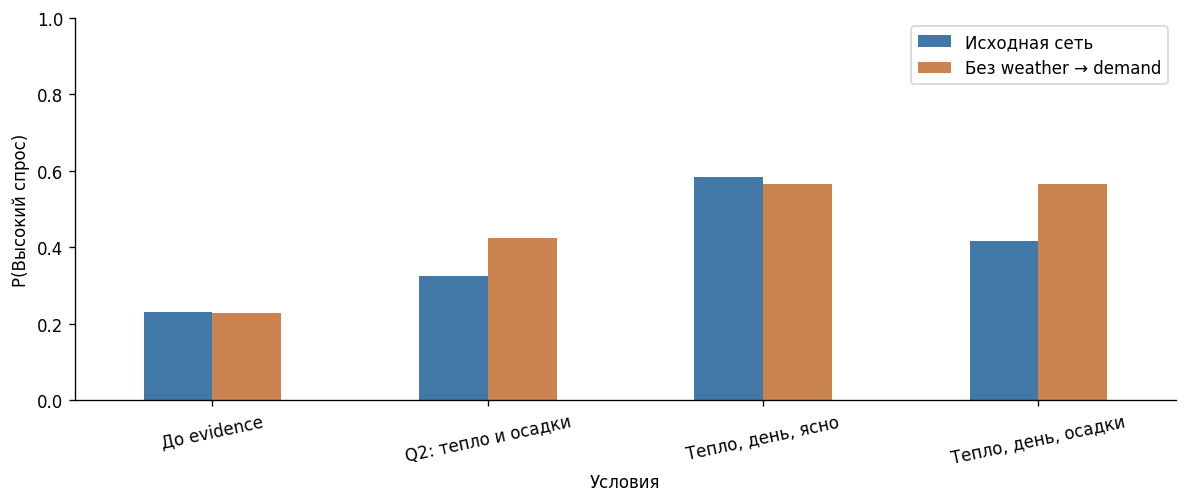

In [13]:
reduced_parents = {node:list(ps) for node, ps in PARENTS.items()}
reduced_parents["demand"].remove("weather")
reduced = DiscreteBayesNet(STATES,reduced_parents,alpha=1.0).fit(data)
structure_rows = []
structure_cases = [("До evidence",{}), ("Q2: тепло и осадки",QUESTIONS[1][3]),
    ("Тепло, день, ясно",{"temperature":"Тепло","period":"День","weather":"Ясно"}),
    ("Тепло, день, осадки",{"temperature":"Тепло","period":"День","weather":"Осадки"})]
for case, ev in structure_cases:
    full_p = float(model.query("demand",ev)["Высокий"])
    reduced_p = float(reduced.query("demand",ev)["Высокий"])
    structure_rows.append({"case":case, "full":full_p, "without_weather_edge":reduced_p,
                           "delta_pp":100*(reduced_p-full_p)})
structure = pd.DataFrame(structure_rows).set_index("case")
display(structure.round(4))
structure.to_csv(RESULTS / "structure_comparison.csv", encoding="utf-8-sig")
np.testing.assert_allclose(reduced.query("demand",structure_cases[2][1]),
                           reduced.query("demand",structure_cases[3][1]))
fig, ax = plt.subplots(figsize=(10,4.3))
structure[["full","without_weather_edge"]].rename(columns={
    "full":"Исходная сеть", "without_weather_edge":"Без weather → demand"
}).plot.bar(ax=ax, color=["#4178a8","#cb8450"], rot=12)
ax.set(ylabel="P(Высокий спрос)", xlabel="Условия", ylim=(0,1))
fig.tight_layout()
fig.savefig(RESULTS / "structure_comparison.png", bbox_inches="tight")
plt.show()

In [14]:
s = structure.loc["Q2: тепло и осадки"]
display(Markdown(f"""
В Q2 вероятность меняется с **{s.full:.1%}** до **{s.without_weather_edge:.1%}**,
то есть на **{s.delta_pp:+.1f} п.п.** CPT спроса теперь усредняет наблюдения разных
погодных условий при одинаковых остальных родителях. Модель теряет возможность
непосредственно учитывать осадки.

Удаление ребра не всегда означает полную независимость погоды и спроса. Остаётся
путь weather ← season → temperature → demand. В Q2 температура известна, но время
суток скрыто: наблюдение коллайдера season → temperature ← period открывает путь
weather ← season → temperature ← period → demand. Даже при заданной температуре
косвенная связь может сохраниться. Если дополнительно зафиксировать **period**,
все такие пути блокируются: две последние строки сокращённой сети совпадают.
В исходной сети остаётся прямая связь.

Это чувствительность к одному структурному предположению, а не доказательство истинности
исходной сети. У сокращённой CPT меньше конфигураций и иное суммарное влияние сглаживания;
используется тот же prior на строку. По наблюдательным данным нельзя однозначно определить
направления всех стрелок: разные DAG могут быть марковски эквивалентны. Для ориентации
нужны дополнительные допущения, временная информация или интервенционные данные.
"""))


В Q2 вероятность меняется с **32.5%** до **42.3%**,
то есть на **+9.8 п.п.** CPT спроса теперь усредняет наблюдения разных
погодных условий при одинаковых остальных родителях. Модель теряет возможность
непосредственно учитывать осадки.

Удаление ребра не всегда означает полную независимость погоды и спроса. Остаётся
путь weather ← season → temperature → demand. В Q2 температура известна, но время
суток скрыто: наблюдение коллайдера season → temperature ← period открывает путь
weather ← season → temperature ← period → demand. Даже при заданной температуре
косвенная связь может сохраниться. Если дополнительно зафиксировать **period**,
все такие пути блокируются: две последние строки сокращённой сети совпадают.
В исходной сети остаётся прямая связь.

Это чувствительность к одному структурному предположению, а не доказательство истинности
исходной сети. У сокращённой CPT меньше конфигураций и иное суммарное влияние сглаживания;
используется тот же prior на строку. По наблюдательным данным нельзя однозначно определить
направления всех стрелок: разные DAG могут быть марковски эквивалентны. Для ориентации
нужны дополнительные допущения, временная информация или интервенционные данные.


### Дополнительно: чувствительность к сглаживанию

Сравним несколько α при неизменной структуре. Это диагностика устойчивости, а не подбор
α по желаемому ответу. Основные результаты остаются при α=1.

In [15]:
sensitivity_rows = []
for alpha in [.1,1.,5.]:
    candidate = DiscreteBayesNet(STATES,PARENTS,alpha=alpha).fit(data)
    sensitivity_rows.append({"alpha":alpha, "prior_high":candidate.query("demand")["Высокий"],
        "Q2_high":candidate.query("demand",QUESTIONS[1][3])["Высокий"],
        "final_evidence_high":candidate.query("demand",evidence_history[-1])["Высокий"]})
sensitivity = pd.DataFrame(sensitivity_rows).set_index("alpha")
display(sensitivity.round(4))
sensitivity.to_csv(RESULTS / "smoothing_sensitivity.csv", encoding="utf-8-sig")
print("Размах вероятностей по alpha, в процентных пунктах:")
print(((sensitivity.max()-sensitivity.min())*100).round(2).to_string())
display(Markdown(
    f"Для Q2 размах по α составляет {(sensitivity.Q2_high.max()-sensitivity.Q2_high.min())*100:.2f} п.п. "
    "Редкие погодные сочетания чувствительны к prior. Число знаков после запятой "
    "в таблицах отражает точность вычисления, а не статистическую уверенность."
))


,prior_high,Q2_high,final_evidence_high
alpha,,,
0.1,0.2265,0.3060,0.3161
1.0,0.2298,0.3250,0.3182
5.0,0.2400,0.3376,0.3235


Размах вероятностей по alpha, в процентных пунктах:
prior_high             1.35
Q2_high                3.16
final_evidence_high    0.75


Для Q2 размах по α составляет 3.16 п.п. Редкие погодные сочетания чувствительны к prior. Число знаков после запятой в таблицах отражает точность вычисления, а не статистическую уверенность.

## 9. Причинность

**Сеть является описательной вероятностной моделью, а не подтверждённой причинной моделью.**
Направления от календаря и погоды к спросу согласуются с временным порядком и бытовыми
механизмами: осадки могут сделать поездку менее удобной. Это основание для гипотезы,
но не доказательство причинного эффекта по данной выборке.

Не наблюдаются инфраструктура, доступность велосипедов, события в городе, световой день
и многие особенности поведения. Год замещает часть этих факторов. Даже физически
правдоподобная стрелка не исключает смешение влияния температуры, сезона и скрытых причин.

$P(D\mid R=осадки)$ описывает знание о спросе среди часов с осадками.
$P(D\mid do(R=осадки))$ описывает вмешательство в механизм погоды и требует причинной
структуры и дополнительных предпосылок. Здесь `do` не вычисляется. Обратный вывод
о температуре по спросу показывает: вывод против направления стрелок возможен
без обратной причинности.

## 10. Итог и ограничения

- Получено совместное распределение семи переменных; неизвестные величины можно
  исключать суммированием и отвечать на вопросы с неполной информацией.
- Интересны сочетание тепла и осадков, различия дневного спроса по типу дня и уточнение
  знания о температуре после наблюдения высокого спроса.
- Evidence меняет относительные веса состояний и не гарантирует монотонность вероятности.
  При наблюдении всех родителей спроса ответ определяется одной строкой CPT.
- Удаление ребра меняет факторизацию, условные независимости и численные ответы.
  Соответствие новой условной независимости проверено численно.
- Ограничения: ручной DAG, потеря информации при дискретизации, редкие сочетания,
  зависимость от prior, зависимые соседние часы, отсутствующие часы, два года и один сервис.
  Грубые интервалы времени скрывают часы пик.
- Не оценены интервалы неопределённости, чувствительность к порогам дискретизации и качество
  вне выборки. Для интервалов нужен блочный bootstrap с учётом временной зависимости,
  а не независимое пересэмплирование часов. Для прогноза нужны временная проверка и baseline,
  для причинности — дополнительные основания.

Численные итоги ниже формируются из результатов вычислений.

In [16]:
summary = f"""# Итоги лабораторной №4

Данные: UCI Bike Sharing, hour.csv; {len(data)} часов, {raw.dteday.nunique()} дней.
DAG: {len(STATES)} вершин, {sum(map(len,PARENTS.values()))} рёбер; точный перебор {len(model.joint)} состояний.
CPT: posterior mean с симметричным Dirichlet(alpha=1) для каждой конфигурации родителей.

- P(высокий спрос) = {q1.prior:.4f}.
- P(высокий спрос | тепло) = {q1.posterior:.4f}.
- P(высокий спрос | тепло, осадки) = {q2.posterior:.4f}.
- P(высокий спрос | день, рабочий день) = {q3.posterior:.4f}.
- P(тепло) = {q4.prior:.4f}; P(тепло | высокий спрос) = {q4.posterior:.4f}.
- После всех evidence P(высокий спрос) = {last['Высокий']:.4f}; наблюдений: {int(last.n_evidence)}.
- Q2 без weather → demand: {s.without_weather_edge:.4f} (изменение {s.delta_pp:+.2f} п.п.).
- CPT спроса: {int(coverage_d.empty_configs)} пустых и {int(coverage_d.configs_under_20)} конфигураций с n<20.

Описательная модель исторической выборки; прогнозное качество и причинные эффекты не оценивались.

Источник: [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset).
DOI: [10.24432/C5W894](https://doi.org/10.24432/C5W894); лицензия CC BY 4.0.
"""
(RESULTS / "summary.md").write_text(summary,encoding="utf-8")
manifest = {"source_url":"https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip",
    "source_doi":"10.24432/C5W894", "license":"CC BY 4.0", "sha256_hour_csv":DATA_HASH,
    "rows":len(data), "missing_calendar_hours":len(missing_hours), "states":STATES, "parents":PARENTS,
    "alpha_per_state_per_parent_config":1., "temperature_bins":[.35,.65], "demand_bins":[100,300],
    "fit_scope":"all observed hours; descriptive analysis; no predictive test", "python":sys.version.split()[0],
    "versions":{p:metadata.version(p) for p in ["numpy","pandas","matplotlib","nbformat","nbclient","ipykernel"]}}
(RESULTS / "run_manifest.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding="utf-8")
display(Markdown(summary))

# Итоги лабораторной №4

Данные: UCI Bike Sharing, hour.csv; 17379 часов, 731 дней.
DAG: 7 вершин, 8 рёбер; точный перебор 1728 состояний.
CPT: posterior mean с симметричным Dirichlet(alpha=1) для каждой конфигурации родителей.

- P(высокий спрос) = 0.2298.
- P(высокий спрос | тепло) = 0.4060.
- P(высокий спрос | тепло, осадки) = 0.3250.
- P(высокий спрос | день, рабочий день) = 0.2951.
- P(тепло) = 0.2547; P(тепло | высокий спрос) = 0.4501.
- После всех evidence P(высокий спрос) = 0.3182; наблюдений: 19.
- Q2 без weather → demand: 0.4231 (изменение +9.82 п.п.).
- CPT спроса: 1 пустых и 27 конфигураций с n<20.

Описательная модель исторической выборки; прогнозное качество и причинные эффекты не оценивались.

Источник: [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset).
DOI: [10.24432/C5W894](https://doi.org/10.24432/C5W894); лицензия CC BY 4.0.
